# Plot JAXMD benchmark

Average runtime of the reverse-mode gradient for the `jaxmd20` benchmark, per pass pipeline and AD placement.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
# works whether the notebook is run from the repo root or from `results/`
csv = Path("results_JAXMD.csv")
if not csv.exists():
    csv = Path("..") / csv

df = pd.read_csv(csv)
df

,Benchmark Name,Pass Pipeline,Backend,Key,Avg Time,stdev Time,Min Time,Max Time
0,jaxmd20,JaXPipe,cuda,Primal,0.000944,0.000052,0.000903,0.001054
1,jaxmd20,Jax,cuda,Primal,0.000876,0.000058,0.000830,0.001033
2,jaxmd20,HLOOpt,cuda,Primal,0.000962,0.000037,0.000890,0.001038
3,jaxmd20,PartOpt,cuda,Primal,0.000986,0.000077,0.000928,0.001196
4,jaxmd20,IPartOpt,cuda,Primal,0.000963,0.000024,0.000933,0.000999
5,jaxmd20,DefOpt,cuda,Primal,0.000495,0.000017,0.000474,0.000539
6,jaxmd20,IDefOpt,cuda,Primal,0.000499,0.000031,0.000471,0.000579
7,jaxmd20,JaXPipe,cuda,Forward,0.000814,0.000038,0.000791,0.000918
8,jaxmd20,Jax,cuda,Forward,0.001246,0.000056,0.001210,0.001400
9,jaxmd20,HLOOpt,cuda,Forward,0.000807,0.000041,0.000783,0.000920


In [3]:
# CSV key -> group label
KEYS = {
    "PreRev": "Pre AD",
    "PostRev": "Post AD",
    "BothRev": "Pre + Post AD",
}

# CSV pass pipeline -> legend label
PIPELINES = {
    "HLOOpt": "HLO Opts.",
    "DefOpt": "All (No Inline)",
    "IDefOpt": "All (Inline)",
}

COLORS = {
    "HLOOpt": "#fc8d62",
    "DefOpt": "#66c2a5",
    "IDefOpt": "#8da0cb",
}

avg = df.pivot_table(index="Key", columns="Pass Pipeline", values="Avg Time")  # seconds
baseline = avg.loc["BothRev", "Jax"]  # "No opt"

avg.loc[list(KEYS), list(PIPELINES)].assign(**{"No opt (Jax)": baseline})

Pass Pipeline,HLOOpt,DefOpt,IDefOpt,No opt (Jax)
Key,,,,
PreRev,0.001457,0.001420,0.001501,0.004457
PostRev,0.004506,0.003753,0.001596,0.004457
BothRev,0.001527,0.001508,0.001504,0.004457


## Runtime

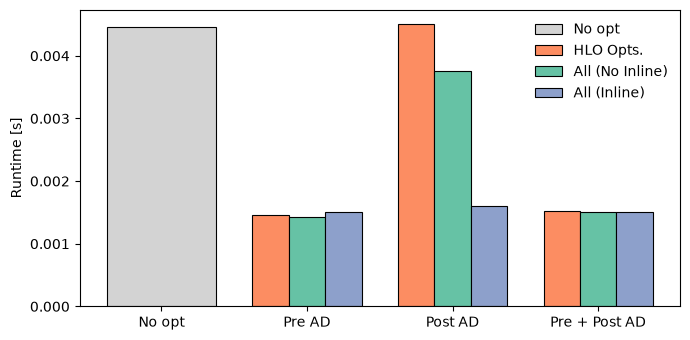

In [4]:
width = 0.25
bar_kw = dict(edgecolor="black", linewidth=0.8)

fig, ax = plt.subplots(figsize=(7, 3.5))

# "No opt" group: single wide bar
ax.bar(0, baseline, width=len(PIPELINES) * width, color="lightgray", label="No opt", **bar_kw)

# Pre AD / Post AD / Pre + Post AD groups
x = np.arange(1, len(KEYS) + 1)
offsets = (np.arange(len(PIPELINES)) - (len(PIPELINES) - 1) / 2) * width
for off, (pipe, label) in zip(offsets, PIPELINES.items()):
    ax.bar(x + off, avg.loc[list(KEYS), pipe], width, color=COLORS[pipe], label=label, **bar_kw)

ax.set_xticks(np.arange(len(KEYS) + 1), ["No opt", *KEYS.values()])
ax.set_ylabel("Runtime [s]")
ax.legend(frameon=False)
fig.tight_layout()

# fig.savefig("jaxmd20-runtime.pdf", bbox_inches="tight")
plt.show()

## Speedup over JAX

In [5]:
# speedup w.r.t. "No opt" (Jax, BothRev): > 1 means faster than the baseline
speedup = (baseline / avg.loc[list(KEYS), list(PIPELINES)]).rename(index=KEYS, columns=PIPELINES)
speedup.round(2)

Pass Pipeline,HLO Opts.,All (No Inline),All (Inline)
Key,,,
Pre AD,3.06,3.14,2.97
Post AD,0.99,1.19,2.79
Pre + Post AD,2.92,2.96,2.96


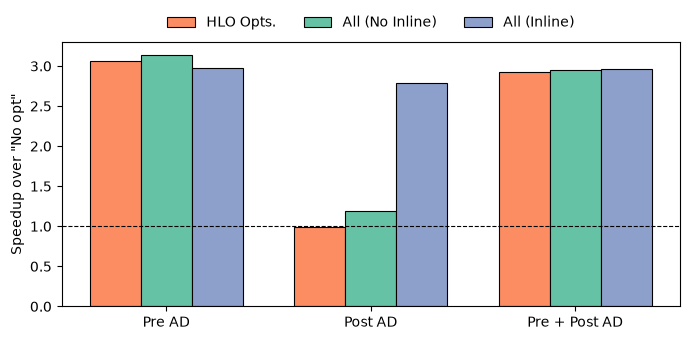

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.5))

x = np.arange(len(KEYS))
for off, (pipe, label) in zip(offsets, PIPELINES.items()):
    ax.bar(x + off, speedup[label], width, color=COLORS[pipe], label=label, **bar_kw)

ax.axhline(1, color="black", linestyle="--", linewidth=0.8)  # "No opt" baseline
ax.set_xticks(x, list(KEYS.values()))
ax.set_ylabel('Speedup over "No opt"')
ax.legend(frameon=False, ncols=len(PIPELINES), loc="lower center", bbox_to_anchor=(0.5, 1.0))
fig.tight_layout()

# fig.savefig("jaxmd20-speedup.pdf", bbox_inches="tight")
plt.show()